# 03 — Modelagem baseline e treinamento inicial no dataset Beans

**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Este notebook cobre a terceira etapa do projeto e é uma **continuação direta do notebook 01**: em vez de repetir a ingestão e o pré-processamento, ele executa o 01 e reaproveita o que foi construído lá (dataset, nomes das classes, `train_ds`, `val_ds` e `test_ds`). A partir daí, constrói e treina uma CNN simples como *baseline*, gera as curvas de aprendizado (loss e acurácia) para o relatório e deixa tudo pronto para comparar o baseline com o modelo final de Transfer Learning.

## 1. Problema e objetivo

Continuamos no mesmo problema de **classificação multiclasse de imagens** (`angular_leaf_spot`, `bean_rust` ou `healthy`), agora consumindo os datasets `train_ds`, `val_ds` e `test_ds` do pipeline definido no notebook 01 (imagens `224 × 224`, pixels em `[0, 1]`).

Os objetivos desta etapa são:

1. construir uma CNN pequena, treinada do zero, que sirva de **ponto de referência (baseline)**;
2. acompanhar a evolução de *loss* e acurácia em treino e validação (curvas de aprendizado);
3. medir o desempenho final no conjunto de teste;
4. salvar métricas e histórico em arquivos, para comparar com o modelo de Transfer Learning.

**Por que uma CNN simples?** Um baseline deve ser fácil de entender e barato de treinar. Se o modelo final de Transfer Learning não superar claramente uma CNN pequena, a complexidade extra não se justifica. O baseline também mostra o quanto um dataset de cerca de mil imagens de treino limita um modelo treinado do zero.

## 2. Continuação do notebook 01

Este notebook parte do que o 01 construiu. A célula abaixo verifica se o 01 já foi executado **nesta sessão do kernel**, procurando as variáveis que o 03 precisa herdar dele:

- configuração: `SEED`, `set_global_seed`, `IMAGE_SIZE`, `BATCH_SIZE` e `output_dir`;
- dados: `dataset`, `labels`, `train_ds`, `val_ds`, `test_ds` e `images`;
- bibliotecas já importadas: `pd`, `plt`, `sns` e `Path`.

Se todas existirem, o 01 **não** é executado de novo e as variáveis são reaproveitadas. Se alguma faltar (primeira execução, kernel reiniciado ou 01 interrompido no meio), o 01 é executado com `%run` no mesmo ambiente deste notebook. As saídas do 01 (tabelas, gráficos e prints) ficam guardadas em `run_01_output`, que mantém este notebook limpo; `run_01_output.show()` as exibe.

Três observações:

- A verificação vale por sessão: cada notebook tem seu próprio kernel, então rodar o 01 em outra aba não conta, e o 03 vai executá-lo uma vez.
- Se você alterar o 01 depois de ele já ter sido executado nesta sessão, reinicie o kernel para que o 03 enxergue a mudança.
- O `%run` de arquivos `.ipynb` exige o pacote `nbformat` instalado.

In [1]:
from IPython.utils.capture import capture_output

inherited = [
    'SEED', 'set_global_seed', 'IMAGE_SIZE', 'BATCH_SIZE', 'output_dir',
    'dataset', 'labels', 'train_ds', 'val_ds', 'test_ds', 'images',
    'pd', 'plt', 'sns', 'Path',
]
run_01_output = None

if [name for name in inherited if name not in globals()]:
    print('Notebook 01 ainda não executado nesta sessão. Executando...')
    with capture_output() as run_01_output:
        get_ipython().run_line_magic('run', '01_data_ingestion_preprocessing.ipynb')
else:
    print('Notebook 01 já executado nesta sessão. Reaproveitando as variáveis.')

missing = [name for name in inherited if name not in globals()]
assert not missing, f'Faltando do notebook 01: {missing}. Verifique se o %run terminou sem erros.'

print('classes:', labels)
print('imagens por split:', {split: len(ds) for split, ds in dataset.items()})
print('image size:', IMAGE_SIZE, '| batch size:', BATCH_SIZE)

Notebook 01 ainda não executado nesta sessão. Executando...
classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
imagens por split: {'train': 1034, 'validation': 133, 'test': 128}
image size: (224, 224) | batch size: 32


## 3. Setup específico do baseline

Aqui entram apenas as bibliotecas e configurações que o 01 não tinha: TensorFlow/Keras, NumPy e o diretório das figuras do relatório. Os artefatos continuam sendo salvos na mesma pasta usada pelo 01 (`output_dir`, ou seja, `data/processed/`).

Há um cuidado com os datasets herdados do 01. `make_tf_dataset` usa `from_generator`, então o TensorFlow não sabe quantos batches cada dataset tem (cardinalidade desconhecida), e o Keras emite um aviso de "input ran out of data" na primeira época. Para evitar esse aviso, informamos o número de batches com `assert_cardinality`. Se o número informado estivesse errado, o TensorFlow levantaria um erro, então a asserção também funciona como uma verificação extra.

Observação: no 01, `val_ds` e `test_ds` foram criados sem `shuffle=False`, então são embaralhados (o padrão de `make_tf_dataset` é `shuffle=True`). Isso não afeta as métricas deste notebook, porque loss e acurácia são médias sobre o conjunto inteiro e, na matriz de confusão, rótulos e previsões são coletados na mesma passada. Por isso não alteramos o 01.

In [2]:
import json
import math
import time

import numpy as np
import tensorflow as tf
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from tensorflow import keras
from tensorflow.keras import layers

ARTIFACTS_DIR = output_dir  # data/processed, definido no notebook 01
FIGURES_DIR = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def with_known_size(tf_ds, n_samples, batch_size):
    n_batches = math.ceil(n_samples / batch_size)
    return tf_ds.apply(tf.data.experimental.assert_cardinality(n_batches))


train_ds = with_known_size(train_ds, len(dataset['train']), BATCH_SIZE)
val_ds = with_known_size(val_ds, len(dataset['validation']), BATCH_SIZE)
test_ds = with_known_size(test_ds, len(dataset['test']), BATCH_SIZE)

print('batches por split:', [int(ds.cardinality()) for ds in (train_ds, val_ds, test_ds)])

batches por split: [33, 5, 4]


## 4. Arquitetura do baseline

A rede é propositalmente pequena:

- **3 blocos** `Conv2D (3×3, ReLU) → MaxPooling2D`, com 16, 32 e 64 filtros. Cada bloco reduz a resolução espacial pela metade e aumenta o número de mapas de características;
- **`GlobalAveragePooling2D`** no lugar de `Flatten`: resume cada mapa em um único valor, o que reduz muito o número de parâmetros e o risco de overfitting;
- **`Dropout(0.3)`** como regularização leve;
- **`Dense(3, softmax)`**: uma probabilidade por classe.

Não usamos data augmentation nesta etapa. A ideia é ter o baseline mais simples possível; se as curvas mostrarem overfitting, isso já é um resultado útil para justificar as etapas seguintes.

In [3]:
def build_baseline_cnn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential(
        [
            keras.Input(shape=input_shape),
            layers.Conv2D(16, 3, padding='same', activation='relu'),
            layers.MaxPooling2D(),
            layers.Conv2D(32, 3, padding='same', activation='relu'),
            layers.MaxPooling2D(),
            layers.Conv2D(64, 3, padding='same', activation='relu'),
            layers.MaxPooling2D(),
            layers.GlobalAveragePooling2D(),
            layers.Dropout(0.3),
            layers.Dense(num_classes, activation='softmax'),
        ],
        name='baseline_cnn',
    )
    return model


set_global_seed(SEED)
model = build_baseline_cnn(input_shape=IMAGE_SIZE + (3,), num_classes=len(labels))
model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Treinamento

Configuração do treino:

- **Otimizador:** Adam com taxa de aprendizado `1e-3` (valor padrão, bom ponto de partida);
- **Loss:** `SparseCategoricalCrossentropy`, porque os rótulos são inteiros (`0`, `1`, `2`) e não one-hot;
- **Métrica:** acurácia, adequada aqui porque as classes estão balanceadas (ver notebook 01);
- **Early stopping:** monitora `val_loss` com paciência de 5 épocas e restaura os pesos da melhor época. Isso evita treinar além do ponto em que o modelo começa a decorar o treino.

Apenas treino e validação participam do treinamento e das decisões. O conjunto de teste só é usado na avaliação final.

In [4]:
EPOCHS = 30
LEARNING_RATE = 1e-3

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

start = time.perf_counter()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    shuffle=False,  # o embaralhamento do treino já é feito em make_tf_dataset
    verbose=2,
)
train_time_s = time.perf_counter() - start
print(f'Tempo total de treino: {train_time_s:.1f} s')

Epoch 1/30
33/33 - 9s - 263ms/step - accuracy: 0.3965 - loss: 1.0893 - val_accuracy: 0.4737 - val_loss: 1.0522
Epoch 2/30
33/33 - 8s - 235ms/step - accuracy: 0.5048 - loss: 1.0335 - val_accuracy: 0.4962 - val_loss: 0.9834
Epoch 3/30
33/33 - 8s - 231ms/step - accuracy: 0.5309 - loss: 0.9782 - val_accuracy: 0.5865 - val_loss: 0.9066
Epoch 4/30
33/33 - 8s - 234ms/step - accuracy: 0.5513 - loss: 0.9498 - val_accuracy: 0.6165 - val_loss: 0.8845
Epoch 5/30
33/33 - 8s - 238ms/step - accuracy: 0.5861 - loss: 0.9040 - val_accuracy: 0.6090 - val_loss: 0.8642
Epoch 6/30
33/33 - 8s - 234ms/step - accuracy: 0.5938 - loss: 0.8959 - val_accuracy: 0.5414 - val_loss: 0.8785
Epoch 7/30
33/33 - 8s - 231ms/step - accuracy: 0.5977 - loss: 0.8915 - val_accuracy: 0.6391 - val_loss: 0.8107
Epoch 8/30
33/33 - 8s - 231ms/step - accuracy: 0.6335 - loss: 0.8487 - val_accuracy: 0.5338 - val_loss: 0.8322
Epoch 9/30
33/33 - 8s - 233ms/step - accuracy: 0.6576 - loss: 0.8159 - val_accuracy: 0.6466 - val_loss: 0.7803
E

In [5]:
history_df = pd.DataFrame(history.history)
history_df.insert(0, 'epoch', range(1, len(history_df) + 1))
history_df

,epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.396518,1.089285,0.473684,1.052182
1,2,0.504836,1.033532,0.496241,0.983428
2,3,0.530948,0.978189,0.586466,0.906586
3,4,0.551257,0.949845,0.616541,0.884484
4,5,0.586074,0.904044,0.609023,0.864163
5,6,0.593810,0.895906,0.541353,0.878486
6,7,0.597679,0.891515,0.639098,0.810658
7,8,0.633462,0.848676,0.533835,0.832168
8,9,0.657640,0.815888,0.646617,0.780343
9,10,0.646035,0.803566,0.654135,0.752401


## 6. Curvas de aprendizado

As curvas comparam treino e validação ao longo das épocas. Para o relatório, vale observar:

- **Loss e acurácia de treino** estão melhorando? Se não, o modelo está subajustado (pequeno demais ou treino curto);
- **Distância entre treino e validação:** um gap grande e crescente indica overfitting;
- **Estabilidade da validação:** com apenas 133 imagens de validação, oscilações de alguns pontos percentuais são esperadas;
- **Época de melhor `val_loss`**, marcada na figura com a linha pontilhada.

A figura é salva em `reports/figures/` para ser incluída diretamente no relatório.

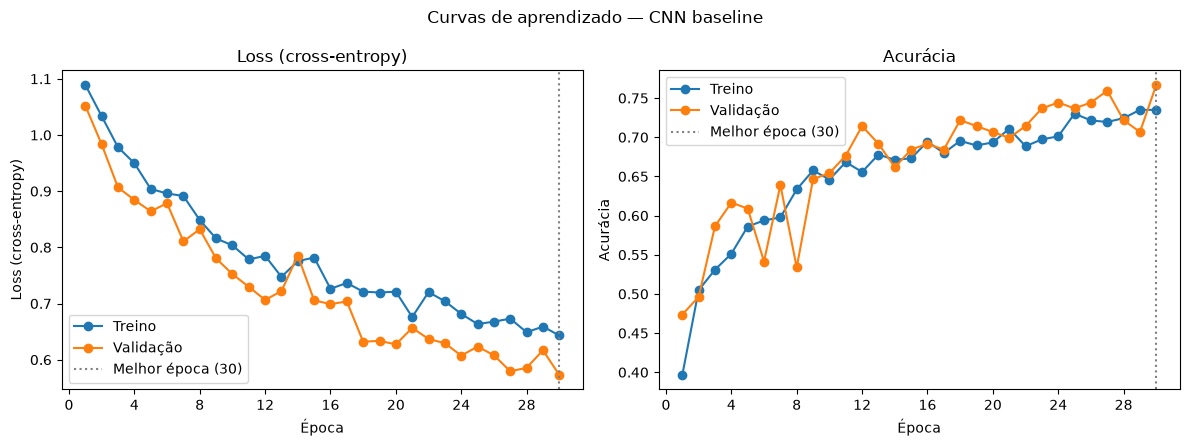

In [6]:
def plot_learning_curves(history_df, title, save_path=None):
    best_epoch = int(history_df.loc[history_df['val_loss'].idxmin(), 'epoch'])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    panels = [('loss', 'Loss (cross-entropy)'), ('accuracy', 'Acurácia')]
    for ax, (metric, ylabel) in zip(axes, panels):
        ax.plot(history_df['epoch'], history_df[metric], marker='o', label='Treino')
        ax.plot(history_df['epoch'], history_df[f'val_{metric}'], marker='o', label='Validação')
        ax.axvline(best_epoch, color='gray', linestyle=':', label=f'Melhor época ({best_epoch})')
        ax.set_title(ylabel)
        ax.set_xlabel('Época')
        ax.set_ylabel(ylabel)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()

    fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return best_epoch


best_epoch = plot_learning_curves(
    history_df,
    title='Curvas de aprendizado — CNN baseline',
    save_path=FIGURES_DIR / 'baseline_learning_curves.png',
)

Para escrever o relatório com números e não só com a impressão visual, resumimos a época de melhor `val_loss` e o gap entre treino e validação nela.

In [7]:
best_row = history_df.loc[history_df['epoch'] == best_epoch].iloc[0]

print(f"Épocas executadas: {len(history_df)}")
print(f"Melhor época (menor val_loss): {best_epoch}")
print(f"Loss      treino: {best_row['loss']:.4f} | validação: {best_row['val_loss']:.4f}")
print(f"Acurácia  treino: {best_row['accuracy']:.4f} | validação: {best_row['val_accuracy']:.4f}")
print(f"Gap de acurácia (treino - validação): {best_row['accuracy'] - best_row['val_accuracy']:+.4f}")

Épocas executadas: 30
Melhor época (menor val_loss): 30
Loss      treino: 0.6431 | validação: 0.5728
Acurácia  treino: 0.7350 | validação: 0.7669
Gap de acurácia (treino - validação): -0.0319


## 7. Avaliação final

Após o treino (com os pesos da melhor época restaurados), avaliamos o modelo em treino, validação e teste. A acurácia de treino é recalculada em modo de inferência (sem dropout), por isso pode diferir da última linha do histórico.

Além da acurácia, calculamos a **matriz de confusão** e **precisão, recall e F1 por classe**. Isso mostra quais classes o modelo confunde, o que a acurácia sozinha esconde.

In [8]:
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

eval_summary = pd.DataFrame(
    {
        'loss': [train_loss, val_loss, test_loss],
        'accuracy': [train_acc, val_acc, test_acc],
    },
    index=['treino', 'validação', 'teste'],
)
eval_summary

,loss,accuracy
treino,0.600369,0.743714
validação,0.572824,0.766917
teste,0.542699,0.757812


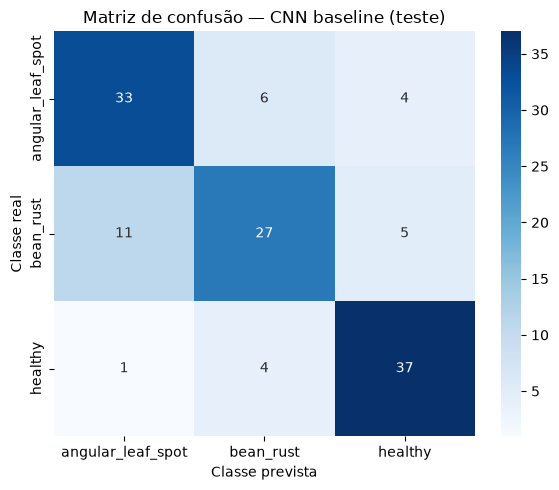

In [9]:
y_true, y_pred = [], []
for batch_images, batch_labels in test_ds:
    probs = model.predict_on_batch(batch_images)
    y_true.append(batch_labels.numpy())
    y_pred.append(np.argmax(probs, axis=1))

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)

cm = tf.math.confusion_matrix(y_true, y_pred, num_classes=len(labels)).numpy()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Matriz de confusão — CNN baseline (teste)')
plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'baseline_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
tp = np.diag(cm)
precision = tp / np.maximum(cm.sum(axis=0), 1)
recall = tp / np.maximum(cm.sum(axis=1), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

per_class = pd.DataFrame(
    {
        'class_name': labels,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'support': cm.sum(axis=1),
    }
)
test_macro_f1 = float(f1.mean())

display(per_class.round(4))
print(f'F1 macro (teste): {test_macro_f1:.4f}')

,class_name,precision,recall,f1,support
0,angular_leaf_spot,0.7333,0.7674,0.7500,43
1,bean_rust,0.7297,0.6279,0.6750,43
2,healthy,0.8043,0.8810,0.8409,42


F1 macro (teste): 0.7553


## 8. Salvando os resultados do baseline

Salvamos o histórico de treino (CSV), as métricas finais (JSON) e o modelo treinado. O histórico e as métricas são o que permite comparar este baseline com o modelo de Transfer Learning sem precisar treinar o baseline de novo.

O JSON de métricas usa chaves simples (`params`, `train_time_s`, `val_accuracy`, `test_accuracy`, `test_macro_f1`, etc.). O notebook do Transfer Learning deve salvar um arquivo com as **mesmas chaves**, para que a seção de comparação funcione.

In [11]:
baseline_metrics = {
    'model': 'CNN baseline',
    'params': int(model.count_params()),
    'epochs_run': int(len(history_df)),
    'best_epoch': int(best_epoch),
    'train_time_s': round(float(train_time_s), 1),
    'train_accuracy': float(train_acc),
    'val_accuracy': float(val_acc),
    'test_accuracy': float(test_acc),
    'val_loss': float(val_loss),
    'test_loss': float(test_loss),
    'test_macro_f1': test_macro_f1,
}

history_df.to_csv(ARTIFACTS_DIR / 'baseline_history.csv', index=False)
per_class.to_csv(ARTIFACTS_DIR / 'baseline_per_class_metrics.csv', index=False)
(ARTIFACTS_DIR / 'baseline_metrics.json').write_text(json.dumps(baseline_metrics, indent=2))
model.save(ARTIFACTS_DIR / 'baseline_cnn.keras')

print('Resultados do baseline salvos em data/processed/.')
baseline_metrics

Resultados do baseline salvos em data/processed/.


{'model': 'CNN baseline',
 'params': 23779,
 'epochs_run': 30,
 'best_epoch': 30,
 'train_time_s': 246.8,
 'train_accuracy': 0.7437137365341187,
 'val_accuracy': 0.7669172883033752,
 'test_accuracy': 0.7578125,
 'val_loss': 0.5728241205215454,
 'test_loss': 0.5426986217498779,
 'test_macro_f1': 0.7553030303030303}

## 9. Checks de qualidade

Checks rápidos para detectar problemas antes de usar os resultados no relatório: formato da saída do modelo, histórico vazio, desempenho abaixo do acaso e artefatos que não foram gravados.

In [14]:
assert model.output_shape == (None, len(labels))
assert len(history_df) >= 1
assert np.allclose(model.predict_on_batch(images).sum(axis=1), 1.0, atol=1e-4)
assert len(y_true) == len(dataset['test'])
assert test_acc > 1 / len(labels), 'Teste abaixo do acaso (33%).'

for filename in [
    'baseline_history.csv',
    'baseline_metrics.json',
    'baseline_cnn.keras',
]:
    assert (ARTIFACTS_DIR / filename).exists(), f'Faltando {filename}'
for filename in ['baseline_learning_curves.png', 'baseline_confusion_matrix.png']:
    assert (FIGURES_DIR / filename).exists(), f'Faltando {filename}'

print('Checks do baseline concluídos com sucesso.')

Checks do baseline concluídos com sucesso.


## 10. Artefatos para as próximas etapas

O notebook deixa prontos: (1) o modelo baseline treinado (`baseline_cnn.keras`), (2) o histórico e as métricas em `data/processed/` (`baseline_history.csv`, `baseline_metrics.json`, `baseline_per_class_metrics.csv`), (3) as figuras do relatório em `reports/figures/` (curvas de aprendizado e matriz de confusão) e (4) a seção de comparação, que completa a tabela e as curvas sobrepostas assim que os resultados do Transfer Learning estiverem disponíveis.